# 01. Дані: CEFR-SP

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sacremoses import MosesDetokenizer
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import train_test_split

SEED = 42
RAW_DIR = Path("../data/raw/cefr-sp")
PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../../docs/figures")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

LEVELS = ["A1", "A2", "B1", "B2", "C"]
NUMBER_TO_LEVEL = {1: "A1", 2: "A2", 3: "B1", 4: "B2", 5: "C", 6: "C"}
SOURCE_FILES = {
    "SCoRE": "CEFR-SP_SCoRE_{split}.txt",
    "Wiki-Auto": "CEFR-SP_Wikiauto_{split}.txt",
}
ORIGINAL_SPLITS = ["train", "dev", "test"]

pd.set_option("display.max_colwidth", 120)

## 1. Завантаження

In [2]:
frames = []
for source, pattern in SOURCE_FILES.items():
    for split in ORIGINAL_SPLITS:
        frame = pd.read_csv(
            RAW_DIR / pattern.format(split=split),
            sep="\t",
            header=None,
            names=["text_tokenized", "label_a", "label_b"],
            quoting=3,
            encoding="utf-8",
        )
        frame["source"] = source
        frame["original_split"] = split
        frames.append(frame)

raw = pd.concat(frames, ignore_index=True)
print(f"Усього речень: {len(raw)}")
raw.groupby(["source", "original_split"]).size().unstack()

Усього речень: 10004


original_split,dev,test,train
source,,,
SCoRE,665,698,1188
Wiki-Auto,701,762,5990


## 2. Детокенізація

In [3]:
detokenizer = MosesDetokenizer(lang="en")
NEGATION_PATTERN = re.compile(r" n't\b")
HYPHEN_PATTERN = re.compile(r"(?<=\w)\s*-\s*(?=\w)")


def detokenize(tokenized_text: str) -> str:
    text = NEGATION_PATTERN.sub("n't", tokenized_text)
    text = detokenizer.detokenize(text.split())
    return HYPHEN_PATTERN.sub("-", text)


raw["text"] = raw["text_tokenized"].map(detokenize)
raw.sample(8, random_state=SEED)[["text_tokenized", "text"]]

,text_tokenized,text
2818,"Juuso died after a long illness on 23 August 2014 , aged 69 .","Juuso died after a long illness on 23 August 2014, aged 69."
4382,Thirty three first person poems that describe various moments during an eleven-year - old boy 's day at the beach .,Thirty three first person poems that describe various moments during an eleven-year-old boy's day at the beach.
7713,"In HVDC monopole configuration , one of the terminals of the rectifier is connected to earth ground .","In HVDC monopole configuration, one of the terminals of the rectifier is connected to earth ground."
8166,Inflationary models and the idea of a theory that unifies quantum mechanics and gravity also are discussed in this c...,Inflationary models and the idea of a theory that unifies quantum mechanics and gravity also are discussed in this c...
4598,Increasing market share is one of the most important objectives in business .,Increasing market share is one of the most important objectives in business.
952,"When the sky began to darken , she closed all the windows and locked the doors .","When the sky began to darken, she closed all the windows and locked the doors."
4043,A large temple also had a lot of land and employed thousands of ordinary people to supply its needs .,A large temple also had a lot of land and employed thousands of ordinary people to supply its needs.
3257,These are by far the most commonly taken exams .,These are by far the most commonly taken exams.


## 3. Згода анотаторів

In [4]:
def agreement_table(frame: pd.DataFrame) -> pd.Series:
    difference = (frame["label_a"] - frame["label_b"]).abs()
    return pd.Series(
        {
            "речень": len(frame),
            "точний збіг": round((difference == 0).mean(), 3),
            "збіг ±1": round((difference <= 1).mean(), 3),
            "каппа (квадратична)": round(
                cohen_kappa_score(frame["label_a"], frame["label_b"], weights="quadratic"), 3
            ),
        }
    )


agreement = pd.concat(
    {"усі": agreement_table(raw), **{s: agreement_table(g) for s, g in raw.groupby("source")}},
    axis=1,
)
agreement

,усі,SCoRE,Wiki-Auto
речень,10004.000,2551.000,7453.000
точний збіг,0.414,0.377,0.427
збіг ±1,1.000,1.000,1.000
каппа (квадратична),0.750,0.536,0.695


## 4. Підсумковий рівень

In [5]:
raw["label_max"] = raw[["label_a", "label_b"]].max(axis=1)
raw["level"] = raw["label_max"].map(NUMBER_TO_LEVEL)
raw["level_id"] = raw["level"].map({level: index for index, level in enumerate(LEVELS)})
raw["n_words"] = raw["text_tokenized"].str.split().map(
    lambda tokens: sum(any(ch.isalnum() for ch in token) for token in tokens)
)
raw[["text", "label_a", "label_b", "level", "n_words"]].head()

,text,label_a,label_b,level,n_words
0,Is that your bike?,1,1,A1,4
1,She had a beautiful necklace around her neck.,1,1,A1,8
2,I forgot to bring my umbrella.,1,1,A1,6
3,The baby kept crying.,1,1,A1,4
4,Do you know what you're doing this weekend?,1,1,A1,9


## 5. Дублікати і короткі речення

In [6]:
duplicate_mask = raw.duplicated("text", keep=False)
print(f"Речень, що повторюються: {duplicate_mask.sum()}")
print(f"Груп дублікатів з різними рівнями: {(raw[duplicate_mask].groupby('text')['level'].nunique() > 1).sum()}")

data = (
    raw.sort_values("label_max", ascending=False)
    .drop_duplicates("text", keep="first")
    .sort_index()
    .reset_index(drop=True)
)
print(f"Після видалення дублікатів: {len(data)}")
print(f"Речень з 1–2 слів: {(data['n_words'] <= 2).sum()}")

Речень, що повторюються: 2
Груп дублікатів з різними рівнями: 0
Після видалення дублікатів: 10003
Речень з 1–2 слів: 0


## 6. Розподіл рівнів

In [7]:
level_counts = pd.crosstab(data["level"], data["source"]).reindex(LEVELS)
level_counts["усього"] = level_counts.sum(axis=1)
level_counts["частка"] = (level_counts["усього"] / len(data)).round(3)
level_counts

source,SCoRE,Wiki-Auto,усього,частка
level,,,,
A1,73,51,124,0.012
A2,947,324,1271,0.127
B1,1273,2031,3304,0.330
B2,243,3087,3330,0.333
C,15,1959,1974,0.197


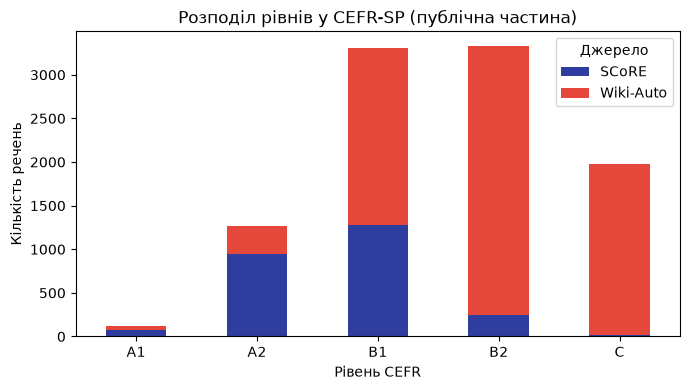

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
level_counts[["SCoRE", "Wiki-Auto"]].plot.bar(stacked=True, ax=ax, color=["#2F3E9E", "#E5483B"], rot=0)
ax.set_xlabel("Рівень CEFR")
ax.set_ylabel("Кількість речень")
ax.set_title("Розподіл рівнів у CEFR-SP (публічна частина)")
ax.legend(title="Джерело")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_level_distribution.png", dpi=150)
plt.show()

## 7. Довжина речень

In [9]:
data.groupby("level")["n_words"].describe().reindex(LEVELS).round(1)

,count,mean,std,min,25%,50%,75%,max
level,,,,,,,,
A1,124.0,7.2,2.8,4.0,5.0,6.5,10.0,15.0
A2,1271.0,7.8,2.9,4.0,6.0,7.0,9.0,24.0
B1,3304.0,11.6,4.5,4.0,8.0,11.0,14.0,28.0
B2,3330.0,15.3,5.3,4.0,11.0,15.0,19.0,30.0
C,1974.0,16.5,5.6,4.0,12.0,16.0,21.0,31.0


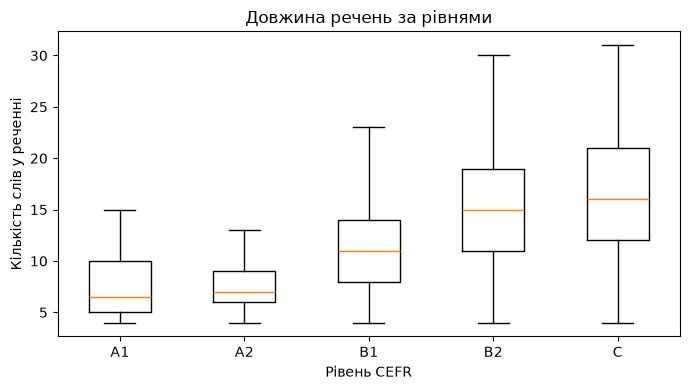

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([data.loc[data["level"] == level, "n_words"] for level in LEVELS], tick_labels=LEVELS, showfliers=False)
ax.set_xlabel("Рівень CEFR")
ax.set_ylabel("Кількість слів у реченні")
ax.set_title("Довжина речень за рівнями")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_length_by_level.png", dpi=150)
plt.show()

In [11]:
data.groupby(["source", "level"])["n_words"].median().unstack().reindex(columns=LEVELS)

level,A1,A2,B1,B2,C
source,,,,,
SCoRE,5.0,7.0,9.0,11.0,11.0
Wiki-Auto,11.0,9.0,12.0,15.0,16.0


## 8. Розбиття train / validation / test

In [12]:
strata = data["source"] + "_" + data["level"]
train, holdout = train_test_split(data, test_size=0.30, stratify=strata, random_state=SEED)
validation, test = train_test_split(
    holdout, test_size=0.50, stratify=strata.loc[holdout.index], random_state=SEED
)

splits = {"train": train, "validation": validation, "test": test}
split_summary = pd.DataFrame(
    {name: frame["level"].value_counts(normalize=True).reindex(LEVELS).round(3) for name, frame in splits.items()}
)
split_summary.loc["речень"] = [len(frame) for frame in splits.values()]
split_summary

,train,validation,test
level,,,
A1,0.012,0.013,0.012
A2,0.127,0.127,0.127
B1,0.330,0.330,0.330
B2,0.333,0.333,0.333
C,0.197,0.198,0.197
речень,7002.000,1500.000,1501.000


In [13]:
assert not set(train["text"]) & set(validation["text"])
assert not set(train["text"]) & set(test["text"])
assert not set(validation["text"]) & set(test["text"])

columns = [
    "text", "level", "level_id", "label_a", "label_b", "label_max",
    "source", "n_words", "original_split", "text_tokenized",
]
for name, frame in splits.items():
    frame[columns].sort_index().to_csv(PROCESSED_DIR / f"cefr_sp_{name}.csv", index=False, encoding="utf-8")
    print(f"{name}: {len(frame)} речень -> {PROCESSED_DIR / f'cefr_sp_{name}.csv'}")

train: 7002 речень -> ..\data\processed\cefr_sp_train.csv
validation: 1500 речень -> ..\data\processed\cefr_sp_validation.csv
test: 1501 речень -> ..\data\processed\cefr_sp_test.csv


## 9. Висновки

- 10 003 речення після видалення дублікатів; train 7002, validation 1500, test 1501.
- Точний збіг анотаторів 41%, ±1 рівень 100%, квадратична каппа 0.75.
- Дисбаланс: A1 1.2%, A2 12.7%, B1 33.0%, B2 33.3%, C 19.7%.
- A1–A2 переважно з SCoRE, B2–C майже лише з Wiki-Auto.
- Медіана довжини: 7 слів (A1–A2) → 16 слів (C).
- Мінімальна довжина речення — 4 слова.